# Market Impact vs Alpha Decay: Execution Strategy Analysis

This project measures the average alpha lost when forced to split orders by comparing different execution strategies based on order book imbalance and other high-frequency signals. Using post-trade markouts, we record both price impact and drift over short periods.

**Data:** MBP-10 tick data for AMZN sourced from Databento (XNAS.ITCH dataset)  
**Period:** March 25-27, 2026

In [1]:
# import sys
# sys.path.insert(0, '..')
from data_collection.data_adapters import DatabentoGenericAdapter
from saf_lib.execution import (
    compute_features, compute_markouts, markout_by_signal,
    ExecutionSimulator, compare_strategies,
    plot_markout_curves, plot_strategy_comparison,
    plot_book_imbalance_vs_markout, plot_impact_vs_alpha_decay,
    plot_spread_and_imbalance_timeseries
)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['figure.dpi'] = 100

## 1. Data Ingestion Pipeline

Load MBP-10 tick data from cache and reconstruct top-of-book pricing and trade flow features.

**MBP-10** (Market-By-Price, 10 levels) data captures the full depth of the limit order book at each update — every time a quote is added, cancelled, modified, or a trade executes. Each row records the 10 best bid and ask price levels along with their sizes.

**Features**:
- **Mid-price**: the average of the best bid and best ask — our benchmark for "fair value" at any given tick.
- **Micro-price**: a size-weighted mid-price that tilts toward the side with more liquidity (e.g., if the bid has more shares than the ask, the micro-price is slightly below the mid). This is a better estimate of where the "true" price sits.
- **Spread (bps)**: the bid-ask spread in basis points — the immediate cost of crossing the spread to trade.
- **Trade flow**: signed trade volume. Trades at or above the ask are classified as buyer-initiated (+), at or below the bid as seller-initiated (−). This captures the net direction of aggressive order flow.
- **Order Book Imbalance (OBI)**: the ratio of bid size minus ask size to total size, computed both at the top-of-book (level 0) and across all 10 depth levels. A positive OBI suggests more resting buy interest, which empirically predicts short-term upward price movement.

In [2]:
from data_collection.data_adapters import DatabentoGenericAdapter
from dotenv import load_dotenv
import os

load_dotenv()

adapter = DatabentoGenericAdapter(os.getenv("DATABENTO_API_KEY"))
raw_data, map = await adapter.get_data(
    tickers=["CSCO", "AMZN", "DRH"],
    start_date="2026-03-25",
    end_date="2026-03-27",
    dataset="XNAS.ITCH",
    schema="MBP-10",
    cache_only=False
)
map = {v: k for k,v in map.items()}

print(f"File size (gb): {raw_data.estimated_size('gb'):.2f}")
raw_data.sample(5, seed=42)


[GenericAdapter] Parquet cache hit: 60d62a7c199464dd86f0005153bcd895.parquet
File size (gb): 2.61


ts_recv,ts_event,rtype,publisher_id,instrument_id,action,side,depth,price,size,flags,ts_in_delta,sequence,bid_px_00,ask_px_00,bid_sz_00,ask_sz_00,bid_ct_00,ask_ct_00,bid_px_01,ask_px_01,bid_sz_01,ask_sz_01,bid_ct_01,ask_ct_01,bid_px_02,ask_px_02,bid_sz_02,ask_sz_02,bid_ct_02,ask_ct_02,bid_px_03,ask_px_03,bid_sz_03,ask_sz_03,bid_ct_03,ask_ct_03,bid_px_04,ask_px_04,bid_sz_04,ask_sz_04,bid_ct_04,ask_ct_04,bid_px_05,ask_px_05,bid_sz_05,ask_sz_05,bid_ct_05,ask_ct_05,bid_px_06,ask_px_06,bid_sz_06,ask_sz_06,bid_ct_06,ask_ct_06,bid_px_07,ask_px_07,bid_sz_07,ask_sz_07,bid_ct_07,ask_ct_07,bid_px_08,ask_px_08,bid_sz_08,ask_sz_08,bid_ct_08,ask_ct_08,bid_px_09,ask_px_09,bid_sz_09,ask_sz_09,bid_ct_09,ask_ct_09,symbol
"datetime[ns, UTC]","datetime[ns, US/Eastern]",u8,u16,u32,str,str,u8,f64,u32,u8,i32,u32,f64,f64,u32,u32,u32,u32,f64,f64,u32,u32,u32,u32,f64,f64,u32,u32,u32,u32,f64,f64,u32,u32,u32,u32,f64,f64,u32,u32,u32,u32,f64,f64,u32,u32,u32,u32,f64,f64,u32,u32,u32,u32,f64,f64,u32,u32,u32,u32,f64,f64,u32,u32,u32,u32,f64,f64,u32,u32,u32,u32,str
2026-03-26 16:27:23.743499457 UTC,2026-03-26 12:27:23.743336758 EDT,10,2,853,"""C""","""B""",1,210.47,100,128,162699,586112437,210.48,210.5,178,140,3,2,210.47,210.51,140,280,2,3,210.46,210.52,140,341,2,5,210.45,210.53,241,298,4,5,210.44,210.54,444,266,7,5,210.43,210.55,640,345,10,5,210.42,210.56,325,486,5,6,210.41,210.57,206,409,3,6,210.4,210.58,129,492,4,7,210.39,210.59,205,206,2,3,"""AMZN"""
2026-03-25 16:40:02.234200679 UTC,2026-03-25 12:40:02.234037829 EDT,10,2,3745,"""A""","""A""",0,81.78,100,128,162850,650042993,81.77,81.78,262,218,4,3,81.76,81.79,780,270,8,4,81.75,81.8,518,270,8,4,81.74,81.81,816,225,9,6,81.73,81.82,1053,416,8,8,81.72,81.83,639,1118,7,11,81.71,81.84,339,716,7,10,81.7,81.85,415,1317,7,8,81.69,81.86,568,424,11,7,81.68,81.87,240,360,6,6,"""CSCO"""
2026-03-26 19:52:17.091093488 UTC,2026-03-26 15:52:17.090928465 EDT,10,2,853,"""A""","""B""",0,207.86,50,128,165023,943693264,207.86,207.87,50,268,1,5,207.85,207.88,156,452,5,5,207.84,207.89,355,334,5,4,207.83,207.9,255,252,4,3,207.82,207.91,257,325,4,5,207.81,207.92,403,468,6,7,207.8,207.93,364,306,6,4,207.79,207.94,420,226,10,4,207.78,207.95,305,106,4,2,207.77,207.96,804,171,7,4,"""AMZN"""
2026-03-26 15:02:26.266201183 UTC,2026-03-26 11:02:26.266038536 EDT,10,2,3745,"""A""","""B""",1,82.17,23,128,162647,386913662,82.18,82.19,172,400,3,4,82.17,82.2,303,480,5,6,82.16,82.21,294,997,5,8,82.15,82.22,522,516,9,8,82.14,82.23,518,714,6,7,82.13,82.24,715,714,7,10,82.12,82.25,1114,485,7,9,82.11,82.26,412,938,7,9,82.1,82.27,414,613,6,8,82.09,82.28,515,932,7,11,"""CSCO"""
2026-03-26 16:09:37.208786217 UTC,2026-03-26 12:09:37.208622619 EDT,10,2,853,"""A""","""B""",4,210.98,100,128,163598,545433698,211.02,211.05,146,241,2,3,211.01,211.06,1046,212,5,4,211.0,211.07,280,320,6,5,210.99,211.08,251,292,4,4,210.98,211.09,239,430,6,7,210.97,211.1,225,409,6,6,210.96,211.11,227,388,4,5,210.95,211.12,306,230,4,6,210.94,211.13,227,225,3,4,210.93,211.14,6,227,1,4,"""AMZN"""


In [3]:
raw_data = raw_data.to_pandas()

In [4]:
df = compute_features(raw_data[raw_data["symbol"] == "AMZN"])
print(f"\nNew features:")
for col in ['mid_price', 'spread', 'spread_bps', 'micro_price', 'trade_flow', 'cumulative_trade_flow', 'obi_level0', 'volume_imbalance']:
    print(f"  {col}: mean={df[col].mean():.4f}, std={df[col].std():.4f}")


New features:
  mid_price: mean=211.0507, std=1.4192
  spread: mean=0.0220, std=0.0109
  spread_bps: mean=1.0436, std=0.5151
  micro_price: mean=211.0509, std=1.4194
  trade_flow: mean=0.0470, std=252.7017
  cumulative_trade_flow: mean=408011.9467, std=186538.7034
  obi_level0: mean=0.0216, std=0.5213
  volume_imbalance: mean=-0.0258, std=0.4477


In [5]:
df

,ts_recv,ts_event,rtype,publisher_id,instrument_id,action,side,depth,price,size,...,ask_ct_09,symbol,mid_price,spread,spread_bps,micro_price,trade_flow,cumulative_trade_flow,obi_level0,volume_imbalance
0,2026-03-25 13:30:00.000285597+00:00,2026-03-25 09:30:00.000121575-04:00,10,2,853,T,N,0,211.66,1,...,1,AMZN,211.665,0.09,4.252002,211.709668,0.0,0.0,0.992620,NaN
1,2026-03-25 13:30:00.001169571+00:00,2026-03-25 09:30:00.001006683-04:00,10,2,853,A,B,0,211.62,100,...,1,AMZN,211.665,0.09,4.252002,211.709757,0.0,0.0,0.994609,NaN
2,2026-03-25 13:30:00.001322597+00:00,2026-03-25 09:30:00.001156040-04:00,10,2,853,T,N,0,211.66,220,...,1,AMZN,211.665,0.09,4.252002,211.709757,0.0,0.0,0.994609,NaN
3,2026-03-25 13:30:00.003351400+00:00,2026-03-25 09:30:00.003182562-04:00,10,2,853,T,N,0,211.65,20,...,1,AMZN,211.665,0.09,4.252002,211.709757,0.0,0.0,0.994609,NaN
4,2026-03-25 13:30:00.003351400+00:00,2026-03-25 09:30:00.003182562-04:00,10,2,853,T,N,0,211.63,468,...,1,AMZN,211.665,0.09,4.252002,211.709757,0.0,0.0,0.994609,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7566985,2026-03-26 19:59:59.972867404+00:00,2026-03-26 15:59:59.972702880-04:00,10,2,853,C,B,0,207.53,37,...,3,AMZN,207.540,0.02,0.963670,207.541879,0.0,268579.0,0.187935,-0.392108
7566986,2026-03-26 19:59:59.978917213+00:00,2026-03-26 15:59:59.978753578-04:00,10,2,853,T,B,0,207.55,4,...,3,AMZN,207.540,0.02,0.963670,207.541879,4.0,268583.0,0.187935,-0.396770
7566987,2026-03-26 19:59:59.978917213+00:00,2026-03-26 15:59:59.978753578-04:00,10,2,853,C,A,0,207.55,4,...,3,AMZN,207.540,0.02,0.963670,207.541991,0.0,268583.0,0.199063,-0.401659
7566988,2026-03-26 19:59:59.979066886+00:00,2026-03-26 15:59:59.978901500-04:00,10,2,853,A,B,0,207.53,4,...,3,AMZN,207.540,0.02,0.963670,207.542065,0.0,268583.0,0.206497,-0.401659


In [6]:
# Summary statistics
print(f"Total ticks: {len(df):,}")
trades = df[df['action'] == 'T']
print(f"Trade events: {len(trades):,} ({len(trades)/len(df)*100:.1f}%)")
print(f"Average spread: {df['spread_bps'].mean():.2f} bps")
print(f"Average book imbalance: {df['book_imbalance'].mean():.4f}")
print(f"Price range: ${df['mid_price'].min():.2f} - ${df['mid_price'].max():.2f}")

Total ticks: 5,714,938
Trade events: 264,630 (4.6%)
Average spread: 1.04 bps


KeyError: 'book_imbalance'

## 2. Exploratory Analysis

KeyError: 'book_imbalance'

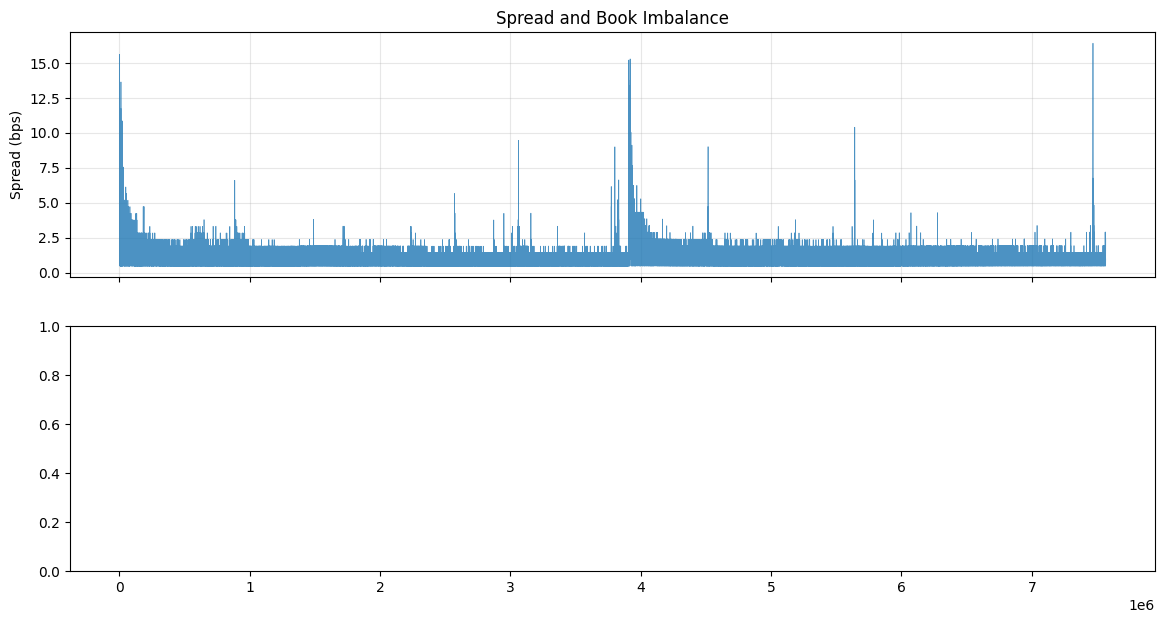

In [7]:
# Visualize a 5-minute window of microstructure dynamics
plot_spread_and_imbalance_timeseries(df, duration_minutes=5.0)
plt.tight_layout()
plt.show()

KeyError: 'book_imbalance'

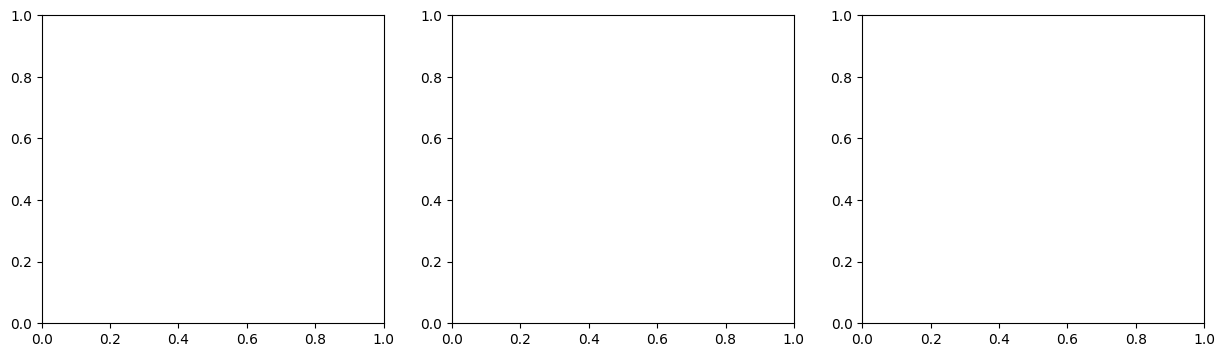

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].hist(df['book_imbalance'].dropna(), bins=100, alpha=0.7, edgecolor='black', linewidth=0.5)
axes[0].set_title('Distribution of Book Imbalance (10 levels)')
axes[0].set_xlabel('Book Imbalance')

axes[1].hist(df['obi_level0'].dropna(), bins=100, alpha=0.7, color='orange', edgecolor='black', linewidth=0.5)
axes[1].set_title('Distribution of Top-of-Book Imbalance')
axes[1].set_xlabel('OBI Level 0')

axes[2].hist(df['spread_bps'].dropna().clip(0, 20), bins=100, alpha=0.7, color='green', edgecolor='black', linewidth=0.5, log=True)
axes[2].set_title('Distribution of Spread (bps)')
axes[2].set_xlabel('Spread (bps)')

plt.tight_layout()
plt.show()

## 3. Markout Analysis

A **markout** measures how the mid-price moves after a given point in time. For each sampled tick, we record the mid-price change at several future horizons. This is the standard tool for evaluating whether a signal predicts short-term price direction.

**How to interpret markout curves:**
- We bin ticks into quantiles by a signal (e.g., book imbalance) and plot the average markout at each horizon for each bin.
- If the top-quintile bin (highest OBI) consistently shows *positive* markouts and the bottom quintile shows *negative* markouts, the signal has predictive power — high OBI predicts upward price movement.
- The spread between the top and bottom quintile curves at a given horizon quantifies the signal's strength in basis points.
- Markouts that grow with horizon suggest persistent alpha while markouts that flatten or revert suggest transient impact.

**Consequences for Execution::**
If OBI predicts a price rise and we are buying, we should trade immediately (before the favorable price disappears). If OBI predicts a decline, we can afford to wait and potentially get a better fill. This is the logic behind the OBI-adaptive execution strategy in Section 4.

In [9]:
# Compute markouts at multiple horizons (sampled for efficiency)
horizons = np.arange(0, 10_010, 10)
markouts = compute_markouts(df, horizons_ms=horizons, sample_n=100_000, seed=42)
print(f"Computed markouts for {len(markouts):,} sampled ticks")
markouts.head()

TypeError: compute_markouts() got an unexpected keyword argument 'horizons_ms'. Did you mean 'horizons_ns'?

In [ ]:
# Markout curves conditioned on full-book imbalance
plot_markout_curves(markouts, signal_col='book_imbalance', n_bins=5)
plt.show()

ValueError: signal_col='book_imbalance' not in markouts_df; available: Index(['ts_recv', 'mid_price', 'obi_level0', 'spread_bps', 'markout_0ms',
       'markout_bps_0ms', 'markout_10ms', 'markout_bps_10ms', 'markout_20ms',
       'markout_bps_20ms',
       ...
       'markout_9960ms', 'markout_bps_9960ms', 'markout_9970ms',
       'markout_bps_9970ms', 'markout_9980ms', 'markout_bps_9980ms',
       'markout_9990ms', 'markout_bps_9990ms', 'markout_10000ms',
       'markout_bps_10000ms'],
      dtype='object', length=2006)

In [ ]:
# Markout curves conditioned on top-of-book imbalance
plot_markout_curves(markouts, signal_col='obi_level0', n_bins=5)
plt.title("Markout Conditional on OBI")
plt.savefig('obi_markout.png', dpi=300, bbox_inches='tight') 
plt.show()

AttributeError: 'DataFrame' object has no attribute 'get_column'

In [ ]:
# Compute markouts at multiple horizons (sampled for efficiency)
horizons = np.arange(0, 100, 1)
markouts = compute_markouts(df, horizons_ms=horizons, sample_n=100_000, seed=42)
print(f"Computed markouts for {len(markouts):,} sampled ticks")
markouts.head()

Computed markouts for 100,000 sampled ticks


,ts_recv,mid_price,obi_level0,spread_bps,markout_0ms,markout_bps_0ms,markout_1ms,markout_bps_1ms,markout_2ms,markout_bps_2ms,...,markout_95ms,markout_bps_95ms,markout_96ms,markout_bps_96ms,markout_97ms,markout_bps_97ms,markout_98ms,markout_bps_98ms,markout_99ms,markout_bps_99ms
0,4,211.665,0.994609,4.252002,0.0,0.0,0.300,14.173340,-0.665,-31.417570,...,-4.125,-194.883424,-4.125,-194.883424,-4.125,-194.883424,-4.125,-194.883424,-4.125,-194.883424
1,17,211.635,-0.980198,3.307581,0.0,0.0,0.320,15.120372,-0.635,-30.004489,...,-4.095,-193.493515,-4.095,-193.493515,-4.095,-193.493515,-4.095,-193.493515,-4.095,-193.493515
2,84,211.635,0.578512,6.142651,0.0,0.0,0.315,14.884117,-0.615,-29.059466,...,-4.095,-193.493515,-4.095,-193.493515,-4.095,-193.493515,-4.095,-193.493515,-4.095,-193.493515
3,115,211.675,-0.577465,6.141490,0.0,0.0,0.290,13.700248,-0.655,-30.943664,...,-4.135,-195.346640,-4.135,-195.346640,-4.135,-195.346640,-4.135,-195.346640,-4.135,-195.346640
4,119,211.665,0.024390,5.196891,0.0,0.0,0.300,14.173340,-0.645,-30.472681,...,-4.125,-194.883424,-4.125,-194.883424,-4.125,-194.883424,-4.125,-194.883424,-4.125,-194.883424


In [ ]:
# Markout curves conditioned on top-of-book imbalance
plot_markout_curves(markouts, signal_col='obi_level0', n_bins=5)
plt.title("Markout Conditional on OBI")
plt.savefig('obi_markout_short.png', dpi=300, bbox_inches='tight') 
plt.show()

AttributeError: 'DataFrame' object has no attribute 'get_column'

### Markout Scatter: OBI vs Future Price Change

The scatter plots below show the direct relationship between book imbalance and the subsequent price movement at 100ms, 1 second (1000ms) and 10 seconds (10_000ms).

Each point represents a bin of ~1,000 ticks with similar book imbalance values. The red dashed line is a linear fit. The slope magnitude is in bps per unit of imbalance.

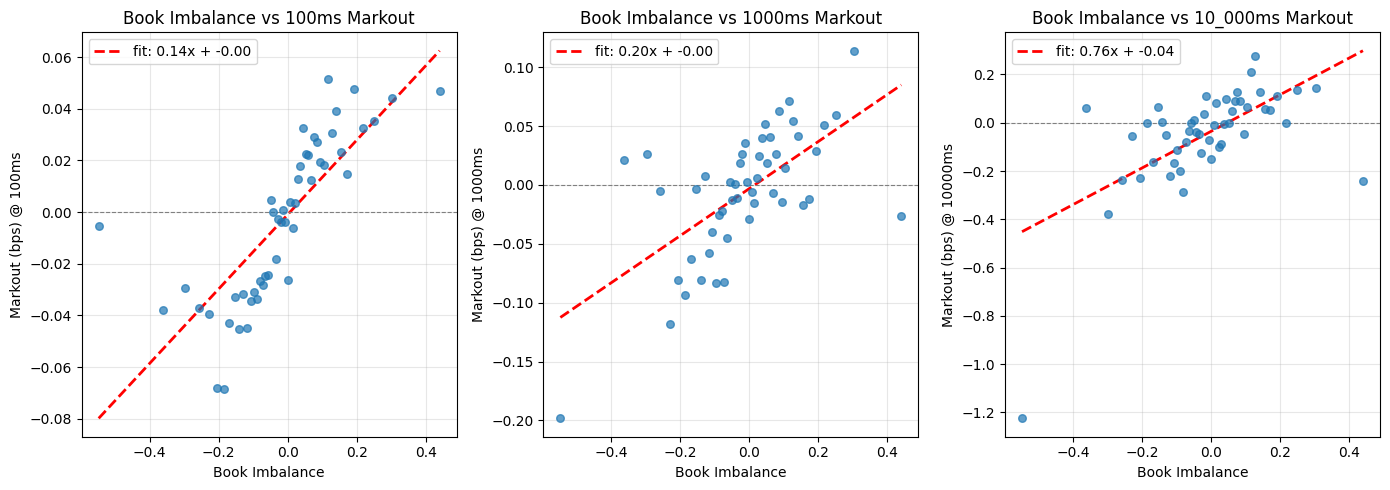

In [ ]:
# Relationship between book imbalance and future price movement
# Using 100ms and 1000ms horizons to capture ultra-short-term dynamics
fig, axes = plt.subplots(1, 3, figsize=(14, 5))

plot_book_imbalance_vs_markout(markouts, horizon_ms=100, ax=axes[0])
axes[0].set_title('Book Imbalance vs 100ms Markout')

plot_book_imbalance_vs_markout(markouts, horizon_ms=1000, ax=axes[1])
axes[1].set_title('Book Imbalance vs 1000ms Markout')

plot_book_imbalance_vs_markout(markouts, horizon_ms=10_000, ax=axes[2])
axes[2].set_title('Book Imbalance vs 10_000ms Markout')


plt.tight_layout()
plt.show()

## 4. Execution Strategy Module

We simulate a parent buy order of 10,000 shares executed over 5 minutes using four strategies:

| Strategy | Logic | Impact | Alpha Decay |
|----------|-------|--------|-------------|
| **Immediate** | Execute everything at the ask in one shot | Highest | None |
| **TWAP** | Split into equal-time slices, execute at the ask each slice | Moderate | Moderate |
| **VWAP** | Weight slices by observed volume — trade more when the market is active | Moderate | Moderate |
| **OBI-Adaptive** | Use book imbalance to vary aggression: aggressive when OBI predicts price will rise (trade before it moves away), passive when OBI predicts price will fall (wait for a better fill) | Variable | Hopefully Minimized |

**Arrival cost** (in bps) = (avg execution price − mid-price at arrival) / arrival mid × 10,000. Positive = paid more than "fair value" at decision time. 
**Fill rate** = fraction of the 10,000-share order that actually executed (since passive orders may not fill).

We run each strategy from 5000 random starting points in the data to get a distribution of outcomes.

**Future Corrections**:
- Currently the arrival cost is calculated using the mid-price as the benchmark, however it's not likely that we would've gotten a fill at the mid. A correction would be to use the Ask price for market buys and the Bid for limit buys.
- We are currently not simulating the price impact as a result of any of these fills. This is especially important for the Immediate strategy. It will appear to have much lower arrival cost, however in practice would move the price dramatically and kill any alpha.

In [ ]:
# Run execution simulations from multiple starting points
results = compare_strategies(
    ExecutionSimulator(df, parent_qty=10_000, horizon_seconds=300.0),
    n_simulations=5000
)
print(results.groupby('strategy')[['arrival_cost_bps', 'fill_rate']].agg(['mean', 'std']))

             arrival_cost_bps           fill_rate          
                         mean       std      mean       std
strategy                                                   
immediate            0.522001  0.270469   1.00000  0.000000
obi_adaptive         0.080956  9.483355   0.98877  0.066485
twap                 0.616248  9.482440   0.99452  0.063677
vwap                 0.613295  9.502200   1.00000  0.000000


In [ ]:
results_pivot = results.pivot(columns="strategy", values="arrival_cost_bps")
results_pivot.describe()

strategy,immediate,obi_adaptive,twap,vwap
count,5000.000000,5000.000000,5000.000000,5000.000000
mean,0.522001,0.080956,0.616248,0.613295
std,0.270469,9.483355,9.482440,9.502200
min,0.234813,-79.196161,-78.174735,-64.961661
25%,0.470898,-5.011452,-4.494166,-4.596917
50%,0.473418,-0.224192,0.283917,0.353921
75%,0.706797,4.973880,5.575807,5.918082
max,5.545777,41.090017,41.804626,40.236917


#### Notes from Jeremy: 
look at the waiting time between fills -> how to calibrate how long you're willing to wait

Before deciding whether it's better or worse, look at ancillary statistics to make sure your thing is mechanically working the way you expect.
(Make it less likely too fill, the waiting time should go up between fills)

Try to implement a fairily naive fill-simulator, like if you send a large order you don't get a fill

Main variables: size of the order, latency. should be able to play with these adn see reasoable results. 0s to 1s latency should change your everything very easily.

Also you cna simulate market orders (no protection) vs a "top level IOC" (market order with price protection at the top level)

**Impact**: simulating the change in the orderbook state if you fill, looking ag how the full book changed after your fills.
THen run a constatn fill system, vs obi fills


For next week: one step fill simulation based on order quantity, price protection, and latency.
How sensitive is the OBI execution strategy to replenishment, latency, and asset selection (3x the stocks he used in lecture, check tick size)

### How to read the results

- **Box plot**: each box shows the distribution of arrival cost across 50 simulations. A tighter box means more consistent execution. A lower median means cheaper execution on average.
- **Impact vs Alpha Decay plot**: each strategy is a point. The x-axis is fill rate (higher = more shares executed), the y-axis is arrival cost. The ideal strategy sits in the **bottom-right** — low cost, high fill rate. Strategies in the top-right pay too much for certainty of execution; those in the bottom-left save money but leave shares on the table.

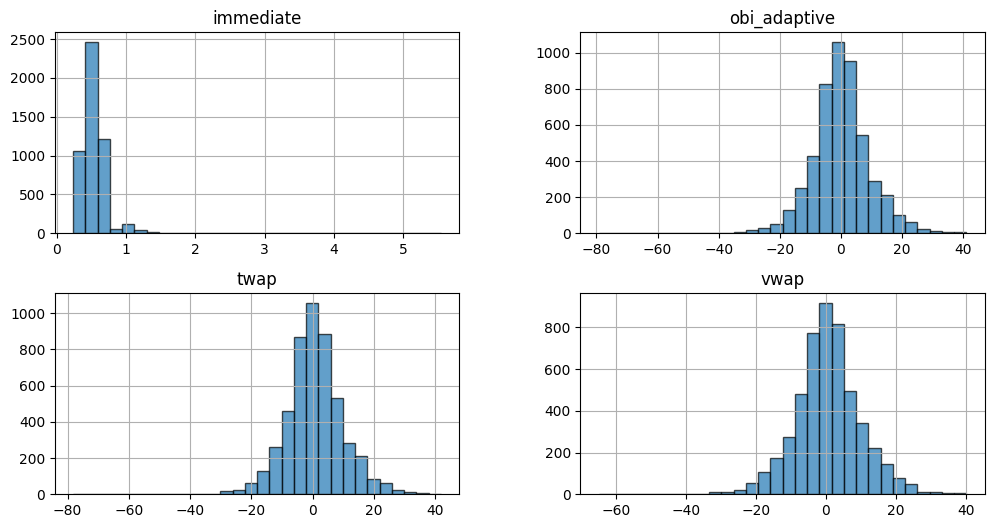

In [ ]:
# plot_strategy_comparison(results)
results_pivot.hist(bins=30, edgecolor="black", color="tab:blue", alpha=0.7)
plt.show()

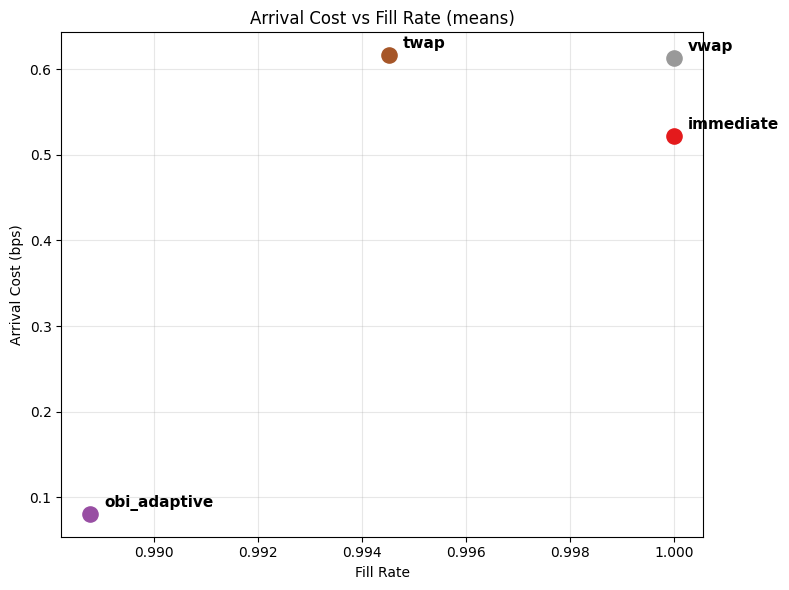

In [ ]:
plot_impact_vs_alpha_decay(results)
plt.show()

## 5. Key Findings

It seems like the obi adaptive strategy did improve the arrival cost of this splitting strategy, with a mean of 0.08bps vs VWAP adn TWAP mean of ~0.60bps. However their standard deviations are nearly identical at 9.48bps, which needs looking into. Also, we are still not simulating price impact, so the immediate fill strategy looks like the bes tbut that is spurious.

In [ ]:
# Markout signal strength
for signal in ['book_imbalance', 'obi_level0']:
    binned = markout_by_signal(markouts, signal_col=signal, n_bins=5)
    spread = binned['markout_bps_1000ms'].iloc[-1] - binned['markout_bps_1000ms'].iloc[0]
    print(f"{signal}: 1s markout spread between top/bottom quintile = {spread:.2f} bps")

print("\n--- Strategy Comparison ---")
summary = results.groupby('strategy')['arrival_cost_bps'].agg(['mean', 'std'])
for strat, row in summary.iterrows():
    print(f"{strat:15s}: {row['mean']:+.2f} \u00b1 {row['std']:.2f} bps")

book_imbalance: 1s markout spread between top/bottom quintile = 0.10 bps
obi_level0: 1s markout spread between top/bottom quintile = 0.34 bps

--- Strategy Comparison ---
immediate      : +0.52 ± 0.27 bps
obi_adaptive   : +0.08 ± 9.48 bps
twap           : +0.62 ± 9.48 bps
vwap           : +0.61 ± 9.50 bps
